# **AI METHODS I**
----
## Step I: Data cleaning and Exploratory Data Analysis (EDA)

### Goals

1. Load the dataset ""global_city_col_qol_index.csv"" from Kaggle directly into **pandas**.

    Steps:    
    a. Choose a python environment    
    b. Set up / Install packages with **.pip** and **import as**                
    c. Set up folders with realitve paths so they can work in any computer     
    d. Import CSV file with **.read()**      
          
2. Inspect the dataset and write a short **dataset card** (source, content, limitations).        

    Steps:    
    a. **.shape** | Number of rows and columns     
    b. **.head()** | The first rows: what the values look like                  
    c. **.info()** | Column names, data types and how many values are *not* missing |   
    d. **.describe()** | Summary statistics (mean, min, max, quartiles…) 
      
3. Detect and fix the classic **data problems**:       
           
    Steps:     
    a. Make a copy of de dataframe with **.copy()**     
    b. Tidy columns names if it's necessary     
    c. Remove all duplicated values with **.duplicated()**       
    d. Get an overview of **missing values()**  
    e. Remove irrelevant columns with **drop.()**    
    f. Fix inconsistent data types and outliers.           


4. **Feature Engineering** 
     
    Steps:     
    a. Extract **temporal features** (If necessary)  
    b. **Create** more features depending on the **relation between existing features**.              
    c. Format or transform variables to ensure they are fully model-ready   

5. **Comparing** raw and clean data sets

6. **(EDA)** Exploring the data with **descriptive statistics** and **visualizations** (matplotlib + seaborn).

    Steps:      
    a.  **Univariate**: one variable at a time    
    b.  **Bivariate**: two variables together       
    c. **Multivariate**: several variables at once      

7. Save a clean, **model-ready dataset** 

### b. Set up / Install packages with **.pip** and **import as**

In [1]:
# Set-up/ install packages.
%pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import installed packages/ libraries into environment?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

### c. Set up folders with realitve paths so they can work in any computer and save images as png

In [3]:
# Set-up folders --- data and figures --- relative paths to enable the notebook to work on any computer.

DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here

DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

In [4]:
# pandas display options 
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# plot style 
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42

In [5]:
# "save_fig()" exports plots as .png 
# Creating a function to call when we need to save a figure (plot during analysis) onto the computer.

def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

### d. Import CSV file with **.read()**

In [6]:
# Import csv file from data folder.
df = pd.read_csv(
    DATA_DIR / "melbourne_house_prices.csv"
)

# print info of imported csv data --- check
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 34,857 rows and 21 columns


# 2. Inspect de dataset - WE NEED TO MAKE CHANGES HERE 

Steps:    
    a. **.shape** | Number of rows and columns     
    b. **.head()** | The first rows: what the values look like                  
    c. **.info()** | Column names, data types and how many values are *not* missing    
    d. **.describe()** | Summary statistics (mean, min, max, quartiles…) 

### Dataset card

| | |
|---|---|
| **Name** | Melbourne House Prices |
| **Source** | Kaggle, [Chaitanya Jamble](https://www.kaggle.com/datasets/chaitanyajamble/global-city-cost-of-living-and-quality-of-life-index) |
| **Origin** |Each city is anchored to the World Bank/IMF public data  |
| **Unit of observation** | ------------Two rows = one **country** of a list of 148 |
| **Size (raw)** | 34,857 Rows by 21 Columns |
| **Target for Day 2** | `quality_of_life_index` (or `qol_category`): overall quality of life score/category for each city |
| **Licence** | Check the *License* field on the Kaggle page before re-using the data in a publication |
| **Known limitations** | Contains synthetic patterns, some columns have missing values (e.g., net salary, traffic, climate), and each city appears twice across different years |

### a. **.shape** | Number of rows and columns  

In [7]:
# Use shape to see number of rows and columns
df.shape

(34857, 21)

### b. **.head()** | The first rows: what the values look like    

In [8]:
# The first 5 rows.
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,68 Studley St,2,h,NaN,SS,Jellis,3/09/2016,2.50,"3,067.00",2.00,1.00,1.00,126.00,NaN,NaN,Yarra City Council,-37.80,145.00,Northern Metropolitan,"4,019.00"
1,Abbotsford,85 Turner St,2,h,"1,480,000.00",S,Biggin,3/12/2016,2.50,"3,067.00",2.00,1.00,1.00,202.00,NaN,NaN,Yarra City Council,-37.80,145.00,Northern Metropolitan,"4,019.00"
2,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,4/02/2016,2.50,"3,067.00",2.00,1.00,0.00,156.00,79.00,"1,900.00",Yarra City Council,-37.81,144.99,Northern Metropolitan,"4,019.00"
3,Abbotsford,18/659 Victoria St,3,u,NaN,VB,Rounds,4/02/2016,2.50,"3,067.00",3.00,2.00,1.00,0.00,NaN,NaN,Yarra City Council,-37.81,145.01,Northern Metropolitan,"4,019.00"
4,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,4/03/2017,2.50,"3,067.00",3.00,2.00,0.00,134.00,150.00,"1,900.00",Yarra City Council,-37.81,144.99,Northern Metropolitan,"4,019.00"


### c. **.info()** | Column names, data types and how many values are *not* missing

In [9]:
# Column names, data types (Dtype) and number of non-missing values per column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34857 entries, 0 to 34856
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         34857 non-null  object 
 1   Address        34857 non-null  object 
 2   Rooms          34857 non-null  int64  
 3   Type           34857 non-null  object 
 4   Price          27247 non-null  float64
 5   Method         34857 non-null  object 
 6   SellerG        34857 non-null  object 
 7   Date           34857 non-null  object 
 8   Distance       34856 non-null  float64
 9   Postcode       34856 non-null  float64
 10  Bedroom2       26640 non-null  float64
 11  Bathroom       26631 non-null  float64
 12  Car            26129 non-null  float64
 13  Landsize       23047 non-null  float64
 14  BuildingArea   13742 non-null  float64
 15  YearBuilt      15551 non-null  float64
 16  CouncilArea    34854 non-null  object 
 17  Lattitude      26881 non-null  float64
 18  Longti

### d. **.describe()** | Summary statistics (mean, min, max, quartiles…)

In [10]:
# .T transposes the table (rows <-> columns) so it is easier to read with many columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Suburb,34857,351,Reservoir,844,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,34857,34009,5 Charles St,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rooms,"34,857.00",NaN,NaN,NaN,3.03,0.97,1.00,2.00,3.00,4.00,16.00
Type,34857,3,h,23980,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,"27,247.00",NaN,NaN,NaN,"1,050,173.34","641,467.13","85,000.00","635,000.00","870,000.00","1,295,000.00","11,200,000.00"
Method,34857,9,S,19744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SellerG,34857,388,Jellis,3359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,34857,78,28/10/2017,1119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance,"34,856.00",NaN,NaN,NaN,11.18,6.79,0.00,6.40,10.30,14.00,48.10
Postcode,"34,856.00",NaN,NaN,NaN,"3,116.06",109.02,"3,000.00","3,051.00","3,103.00","3,156.00","3,978.00"


# 3. Detect and fix the classic data problems:       
           
Steps:     
    a. Make a copy of de dataframe with **.copy()**     
    b. Tidy columns names if it's necessary     
    c. Remove all duplicated values with **.duplicated()**       
    d. Get an overview of **missing values()**  
    e. Remove irrelevant columns with **drop.()**    
    f. Fix inconsistent data types and outliers. 

### a. Make a copy of de dataframe with **.copy()**

In [11]:
# .copy() creates an independent copy: changing df_clean will NOT change df
df_clean = df.copy()

### b. Tidy columns names if it's necessary 

In [12]:
# # Give new names to columns if they are not proper.
# new_names = {"Old_Name":"new_name",
#              "Old_Name_2":"new_name_2"}
# df_clean = df_clean.rename(columns=new_names)
# df_clean.columns.tolist()

### c. Remove all duplicated values with **.duplicated()**       


In [13]:
#Check for duplicates rows in the table
n_duplicates = df_clean.duplicated().sum()
print(f"Number of duplicate rows: {n_duplicates}")

Number of duplicate rows: 1


### d. Get an overview of **missing values()**  
   

In [15]:
#check for missing data in the table(n=missing) and percentage of missing data in the table(pct_missing)
def missing_report(data):
    n_missing = data.isnull().sum()
    pct_missing = (n_missing / len(data)) * 100
    report = pd.DataFrame({
        "n_missing": n_missing,
        "pct_missing": pct_missing  
    })
    return report.sort_values(
        "pct_missing", 
        ascending=False
    )
missing = missing_report(df_clean)
missing

,n_missing,pct_missing
BuildingArea,21115,60.58
YearBuilt,19306,55.39
Landsize,11810,33.88
Car,8728,25.04
Bathroom,8226,23.60
Bedroom2,8217,23.57
Longtitude,7976,22.88
Lattitude,7976,22.88
Price,7610,21.83
Regionname,3,0.01


Figure saved to figures\01_missing_values.png


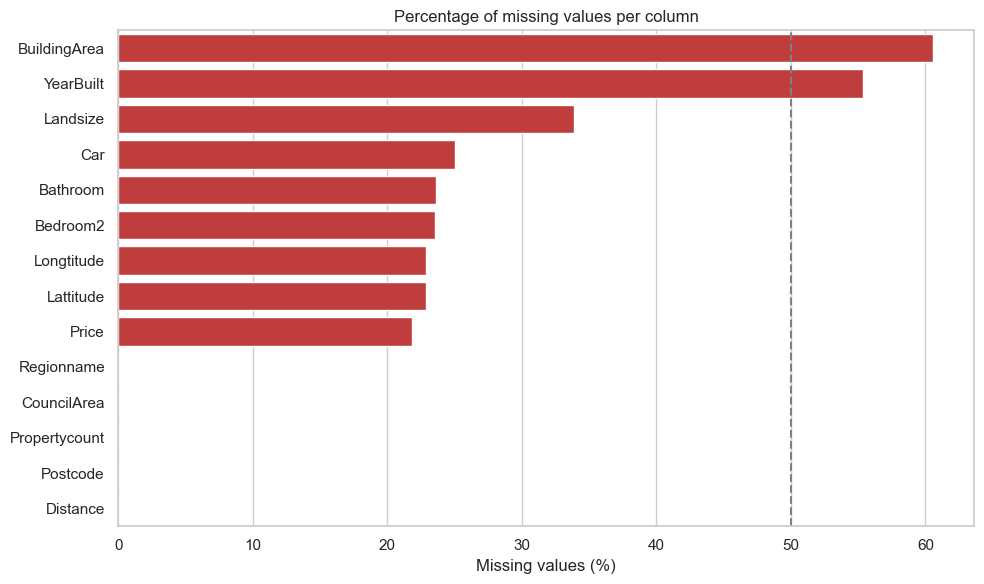

In [16]:
# Easy to understand this with a chart if there is any missing data.
# NONE in this case.

fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

# Can decide what columns to drop based on this analysis.

Check the code below and for columns adn rows to remove. 

In [19]:
# Drop BuildingArea (60.58% missing)
df_clean = df_clean.drop(columns=["BuildingArea"])
df_clean.shape  # should now show 20 columns

(34857, 20)

In [20]:
# Drop rows where Price is missing
print("Missing Price before:", df_clean["Price"].isna().sum())
print("Rows before:", len(df_clean))

df_clean = df_clean.dropna(subset=["Price"])

print("Missing Price after:", df_clean["Price"].isna().sum())
print("Rows after:", len(df_clean))


Missing Price before: 7610
Rows before: 34857
Missing Price after: 0
Rows after: 27247


df_clean now has 27,247 rows and 20 columns
Figure saved to figures\02_missing_values_after_cleaning.png


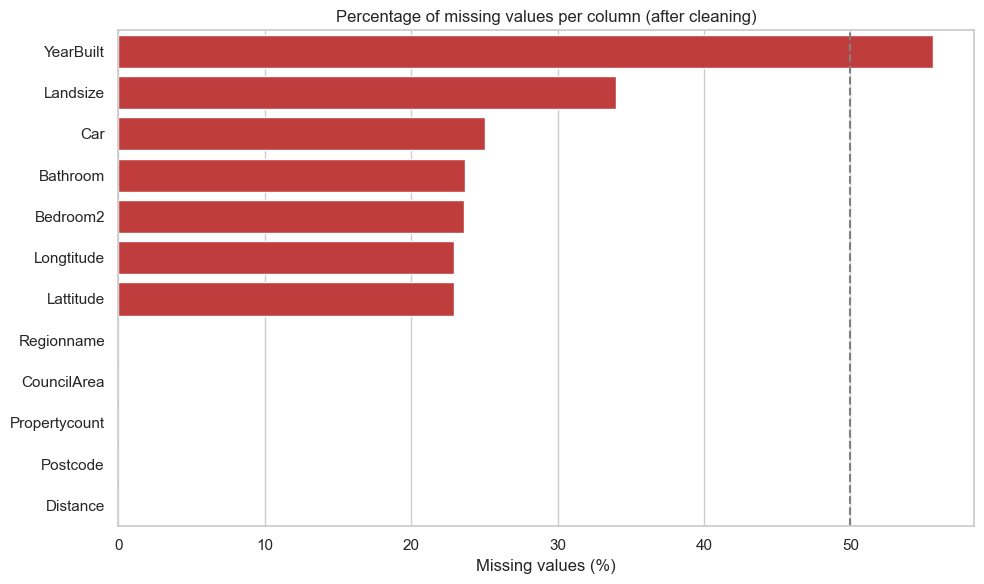

,n_missing,pct_missing
YearBuilt,15163,55.65
Landsize,9265,34.00
Car,6824,25.04
Bathroom,6447,23.66
Bedroom2,6441,23.64
Longtitude,6254,22.95
Lattitude,6254,22.95
Regionname,3,0.01
CouncilArea,3,0.01
Propertycount,3,0.01


In [21]:
# Missing values AFTER removing BuildingArea and rows with missing Price.
# Recalculate the report from df_clean so the chart shows the data as it is now.
missing_after = missing_report(df_clean)
print(f"df_clean now has {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns")

# Only plot the columns that still have at least one missing value
missing_after_to_plot = missing_after[missing_after["pct_missing"] > 0]

if missing_after_to_plot.empty:
    print("No missing values left in df_clean.")
else:
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=missing_after_to_plot, x="pct_missing", y=missing_after_to_plot.index, color="tab:red", ax=ax)
    ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
    ax.set_title("Percentage of missing values per column (after cleaning)")
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("")
    plt.tight_layout()
    save_fig("02_missing_values_after_cleaning")
    plt.show()

missing_after_to_plot


In [22]:
# Drop rows where YearBuilt is missing
print("Missing YearBuilt before:", df_clean["YearBuilt"].isna().sum())
print("Rows before:", len(df_clean))

df_clean = df_clean.dropna(subset=["YearBuilt"])

print("Missing YearBuilt after:", df_clean["YearBuilt"].isna().sum())
print("Rows after:", len(df_clean))


Missing YearBuilt before: 15163
Rows before: 27247
Missing YearBuilt after: 0
Rows after: 12084


df_clean now has 12,084 rows and 20 columns
Figure saved to figures\03_missing_values_all_columns.png


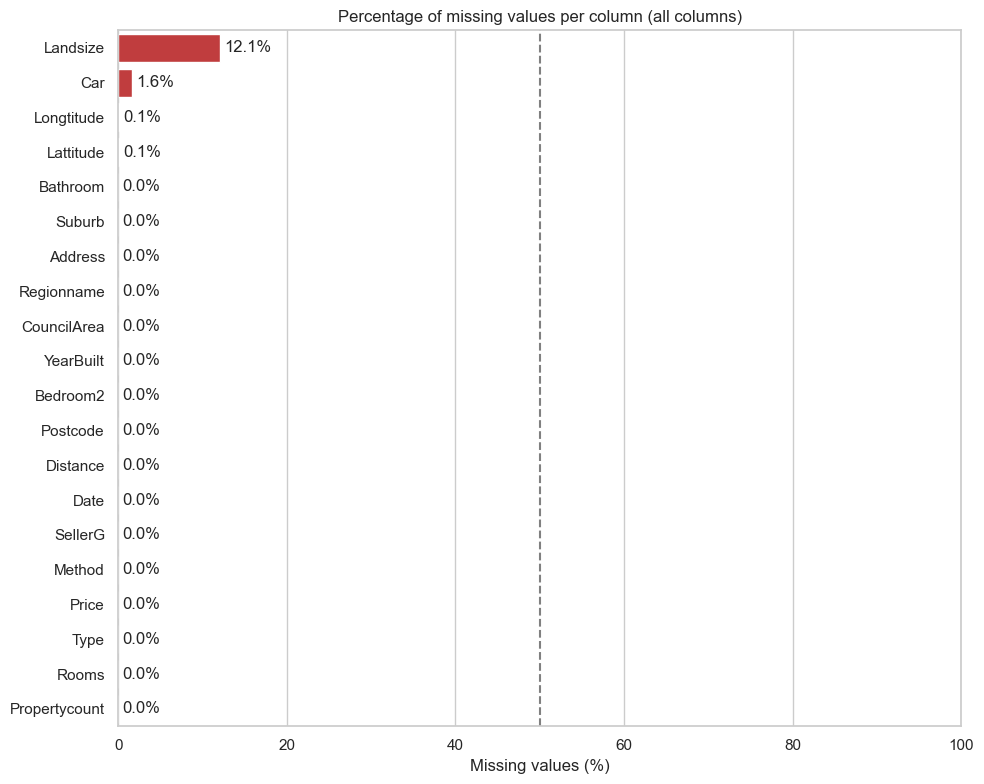

,n_missing,pct_missing
Landsize,1463,12.11
Car,196,1.62
Longtitude,8,0.07
Lattitude,8,0.07
Bathroom,1,0.01
Suburb,0,0.00
Address,0,0.00
Regionname,0,0.00
CouncilArea,0,0.00
YearBuilt,0,0.00


In [24]:
# Missing values for ALL columns (including those with 0 missing)
missing_all = missing_report(df_clean)
print(f"df_clean now has {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns")

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=missing_all, x="pct_missing", y=missing_all.index, color="tab:red", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)   # show the % next to every bar, even 0
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_xlim(0, 100)                            # fixed scale so charts are easy to compare
ax.set_title("Percentage of missing values per column (all columns)")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("03_missing_values_all_columns")
plt.show()

missing_all


In [25]:
# Fill missing Car values with the median
print("Missing Car before:", df_clean["Car"].isna().sum())

car_median = df_clean["Car"].median()
df_clean["Car"] = df_clean["Car"].fillna(car_median)

print(f"Filled with median: {car_median}")
print("Missing Car after:", df_clean["Car"].isna().sum())


Missing Car before: 196
Filled with median: 2.0
Missing Car after: 0


### f. Fix inconsistent data types

Give the date format. 
1. Date is day/month/year. Plain pd.to_datetime() can read 3/09/2016 as March 9 instead of September 3, so the code passes format="%d/%m/%Y".
2. Use "Int64", not "int". Plain int fails if any NaN are left, for example in Bathroom or Bedroom2 if you haven't filled them yet. Int64 allows missing values.
3. Postcode becomes text so it isn't treated as a number. An average postcode means nothing.
4. Two column names are misspelled: Lattitude and Longtitude. They aren't data type problems, but you can fix them in step b, "Tidy column names":

In [26]:
# Fix inconsistent data types
print("--- Before ---")
print(df_clean.dtypes)

# 1. Date: text -> datetime. The dates are day/month/year (3/09/2016 = 3 Sep 2016).
df_clean["Date"] = pd.to_datetime(df_clean["Date"], format="%d/%m/%Y")

# 2. Postcode: a label, not a number to average -> string
df_clean["Postcode"] = df_clean["Postcode"].astype("Int64").astype("string")

# 3. Counts and years: float -> whole numbers.
#    "Int64" (capital I) still allows missing values, so it won't crash if any NaN are left.
int_cols = ["Car", "Bedroom2", "Bathroom", "YearBuilt", "Propertycount"]
df_clean[int_cols] = df_clean[int_cols].round().astype("Int64")

# 4. Repeated text labels -> category (uses less memory, useful for plotting/grouping)
cat_cols = ["Type", "Method", "Regionname", "CouncilArea"]
df_clean[cat_cols] = df_clean[cat_cols].astype("category")

print("\n--- After ---")
print(df_clean.dtypes)


--- Before ---
Suburb            object
Address           object
Rooms              int64
Type              object
Price            float64
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
YearBuilt        float64
CouncilArea       object
Lattitude        float64
Longtitude       float64
Regionname        object
Propertycount    float64
dtype: object

--- After ---
Suburb                   object
Address                  object
Rooms                     int64
Type                   category
Price                   float64
Method                 category
SellerG                  object
Date             datetime64[ns]
Distance                float64
Postcode         string[python]
Bedroom2                  Int64
Bathroom                  Int64
Car                       Int64
Landsize                float64
YearBuil

In [27]:
df_clean = df_clean.rename(columns={"Lattitude": "Latitude", "Longtitude": "Longitude"})


In [28]:
# Check new dataset scope.

print(f"Reduced data scope: {len(df_clean)}")
df_clean.head()

Reduced data scope: 12084


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,YearBuilt,CouncilArea,Latitude,Longitude,Regionname,Propertycount
2,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,2016-02-04,2.50,3067,2,1,0,156.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
4,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,2017-03-04,2.50,3067,3,2,0,134.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
6,Abbotsford,55a Park St,4,h,"1,600,000.00",VB,Nelson,2016-06-04,2.50,3067,3,1,2,120.00,2014,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
11,Abbotsford,124 Yarra St,3,h,"1,876,000.00",S,Nelson,2016-05-07,2.50,3067,4,2,0,245.00,1910,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019
14,Abbotsford,98 Charles St,2,h,"1,636,000.00",S,Nelson,2016-10-08,2.50,3067,2,1,2,256.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019


In [29]:
# check the info and data types of each column in the cleaned table
df_clean.info()
df_clean.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
Index: 12084 entries, 2 to 34856
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Suburb         12084 non-null  object        
 1   Address        12084 non-null  object        
 2   Rooms          12084 non-null  int64         
 3   Type           12084 non-null  category      
 4   Price          12084 non-null  float64       
 5   Method         12084 non-null  category      
 6   SellerG        12084 non-null  object        
 7   Date           12084 non-null  datetime64[ns]
 8   Distance       12084 non-null  float64       
 9   Postcode       12084 non-null  string        
 10  Bedroom2       12084 non-null  Int64         
 11  Bathroom       12083 non-null  Int64         
 12  Car            12084 non-null  Int64         
 13  Landsize       10621 non-null  float64       
 14  YearBuilt      12084 non-null  Int64         
 15  CouncilArea    12084 non

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Suburb,12084,324,Reservoir,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,12084,11909,25 William St,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rooms,"12,084.00",NaN,NaN,NaN,3.06,1.00,2.00,3.00,4.00,12.00,0.97
Type,12084,3,h,8736,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,"12,084.00",NaN,NaN,NaN,"1,077,201.64","85,000.00","632,000.00","885,000.00","1,320,000.00","9,000,000.00","671,327.71"
Method,12084,5,S,7655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SellerG,12084,278,Nelson,1266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,12084,NaN,NaN,NaN,2017-04-28 09:48:19.304866048,2016-02-04 00:00:00,2016-10-15 00:00:00,2017-06-17 00:00:00,2017-10-07 00:00:00,2018-03-17 00:00:00,NaN
Distance,"12,084.00",NaN,NaN,NaN,11.29,0.00,6.40,10.30,14.00,48.10,6.97
Postcode,12084,199,3073,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### f. Fix outliers

Figure saved to figures\04_boxplots_before_outliers.png


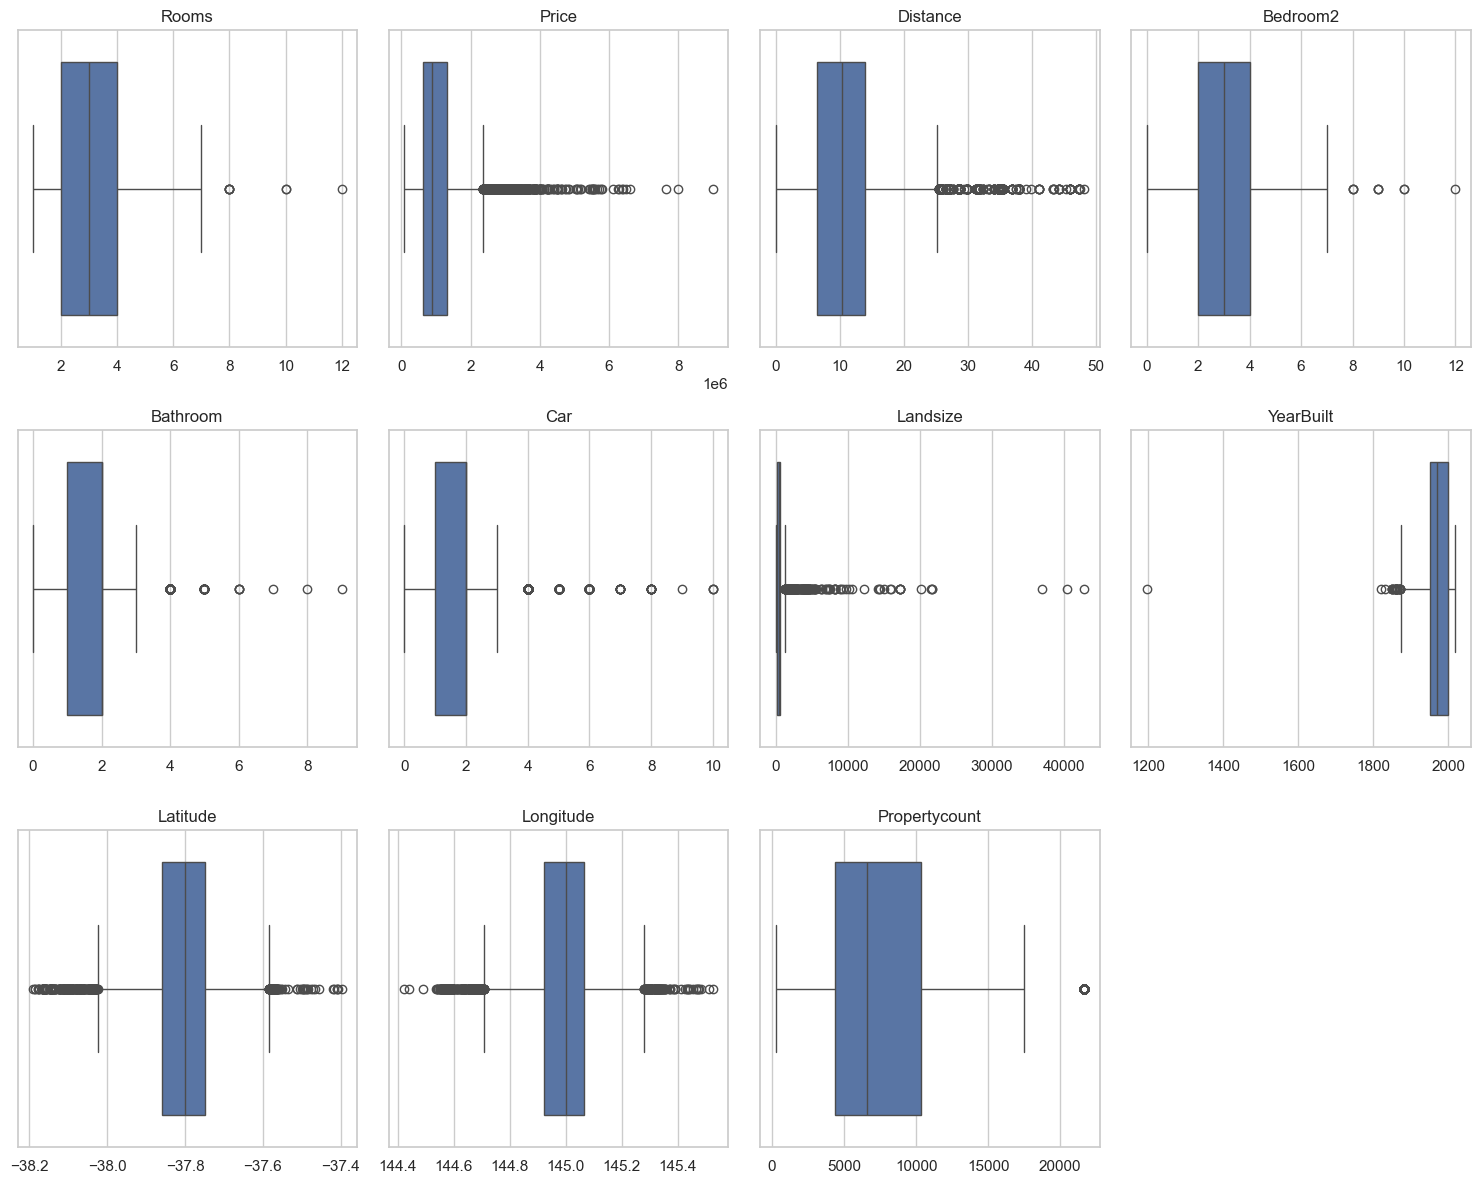

In [30]:
# Inspect the distribution of the numeric columns using boxplots to identify outliers.

# Box -> Middle 50% of values
# Line inside the box -> Median, the middle value
# Whiskers -> Range defined by the boxplot rule (1.5 x IQR)
# Dots beyond the whiskers -> Potential outliers to investigate

def plot_boxplots(data, name):
    num_cols = data.select_dtypes(include="number").columns.tolist()
    n_rows = int(np.ceil(len(num_cols) / 4))

    fig, axes = plt.subplots(n_rows, 4, figsize=(15, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.boxplot(x=data[col].astype(float), ax=axes[i])
        axes[i].set_title(col)
        axes[i].set_xlabel("")

    # Turn off the empty axes in the last row
    for j in range(len(num_cols), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    save_fig(name)
    plt.show()

plot_boxplots(df_clean, "04_boxplots_before_outliers")


In [31]:
# Fix outliers
rows_before = len(df_clean)

# 1. Remove impossible / unrealistic values (rules based on what a house can be).
#    Missing values are kept (they are handled by imputation, not here).
rules = {
    "Rooms":     (1, 10),
    "Bedroom2":  (0, 10),
    "Bathroom":  (1, 8),
    "Car":       (0, 10),
    "YearBuilt": (1800, 2018),   # sales are from 2016-2017, nothing built in the future
}

for col, (low, high) in rules.items():
    keep = (df_clean[col].isna() | df_clean[col].between(low, high)).astype(bool)
    print(f"{col}: removing {(~keep).sum()} rows outside {low}-{high}")
    df_clean = df_clean[keep]

# 2. Landsize: 0 is valid (apartments), but a few huge values (up to 433,014 m²) stretch the data.
#    Cap them at the 99th percentile instead of deleting the rows.
landsize_cap = df_clean["Landsize"].quantile(0.99)
n_capped = (df_clean["Landsize"] > landsize_cap).sum()
df_clean["Landsize"] = df_clean["Landsize"].clip(upper=landsize_cap)
print(f"Landsize: capped {n_capped} values at {landsize_cap:,.0f} m²")

print(f"\nRows before: {rows_before:,} | Rows after: {len(df_clean):,} | Removed: {rows_before - len(df_clean):,}")


Rooms: removing 1 rows outside 1-10
Bedroom2: removing 0 rows outside 0-10
Bathroom: removing 3 rows outside 1-8
Car: removing 0 rows outside 0-10
YearBuilt: removing 2 rows outside 1800-2018
Landsize: capped 107 values at 2,841 m²

Rows before: 12,084 | Rows after: 12,078 | Removed: 6


Figure saved to figures\05_boxplots_after_outliers.png


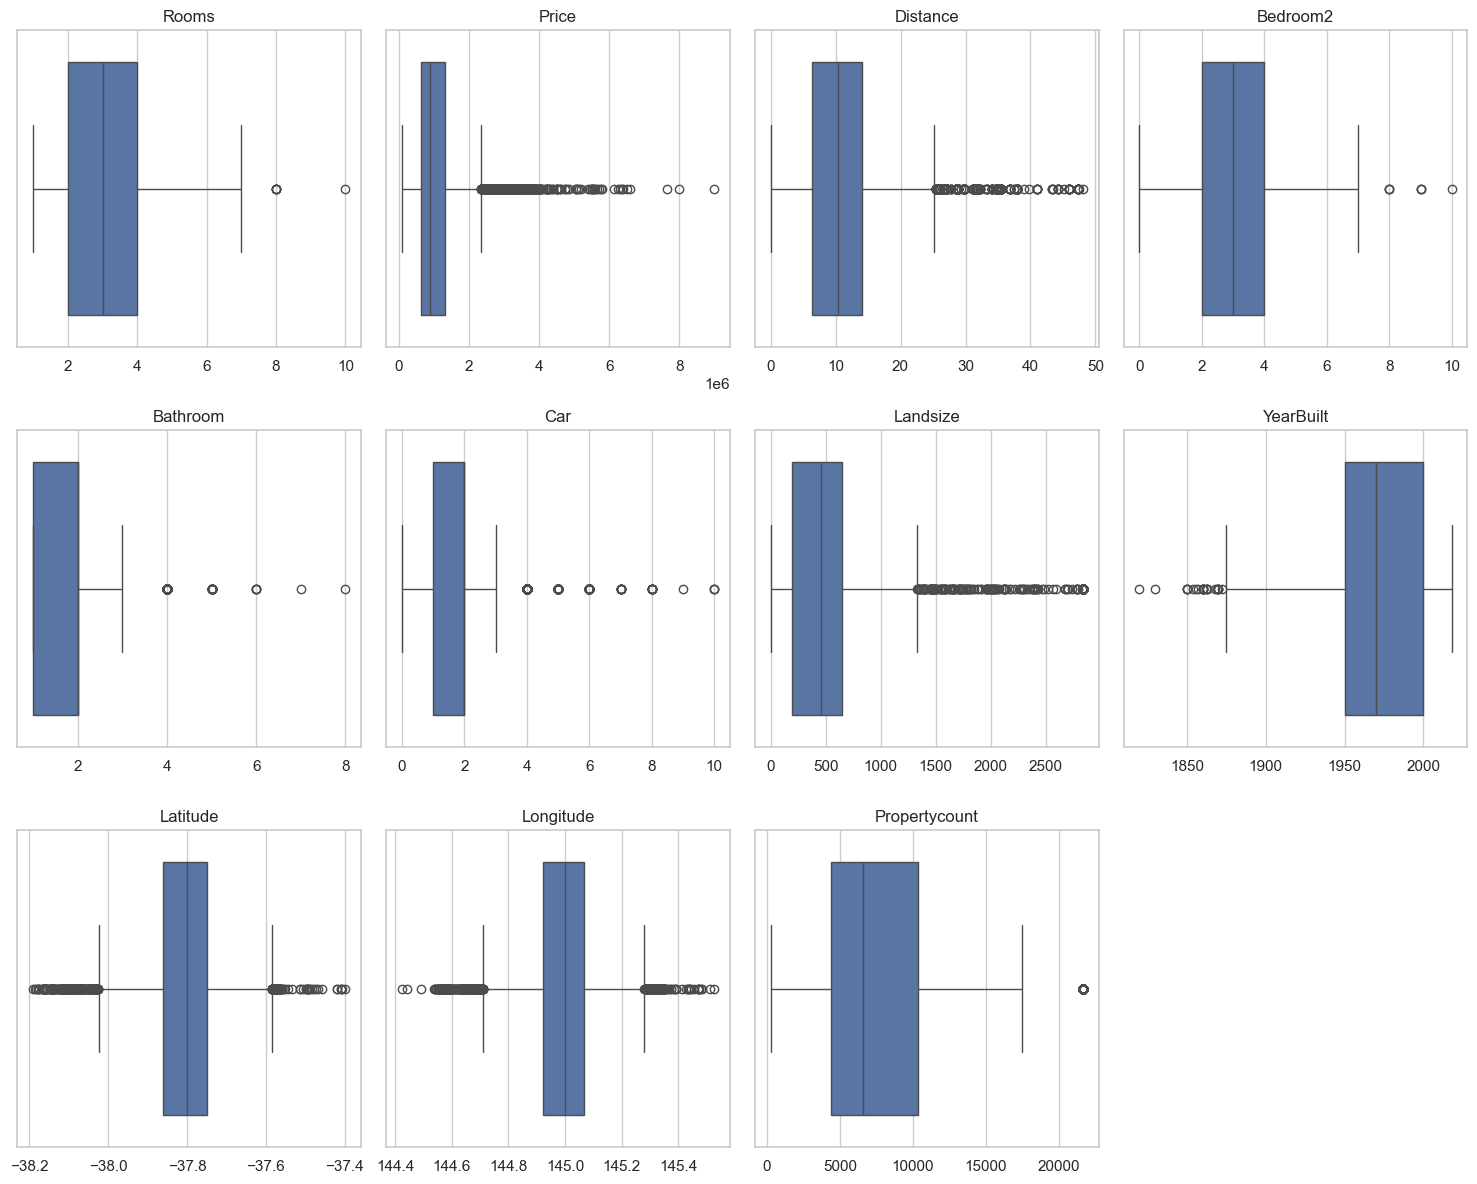

In [32]:
plot_boxplots(df_clean, "05_boxplots_after_outliers")


In [34]:
# This block loops through selected quantitative fields and caps outliers (IQR method)

# Only cap feature columns where extreme values distort the data.
# NOT capped:
#   - Price: the target; expensive houses are real sales
#   - Lattitude / Longtitude: locations, not measurements
#   - Propertycount: number of properties in the suburb, not a property feature
#   - YearBuilt: already cleaned with a 1800-2018 rule; old houses are real
cols_to_cap = ["Rooms", "Distance", "Bedroom2", "Bathroom", "Car", "Landsize"]

# Keep only the columns that exist in df_clean (in case one was dropped earlier)
cols_to_cap = [col for col in cols_to_cap if col in df_clean.columns]

# Loop through each column and cap outliers
for col in cols_to_cap:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Whole-number columns (Int64) can't hold decimals, so round the bounds outward
    if pd.api.types.is_integer_dtype(df_clean[col]):
        lower_bound = int(np.floor(lower_bound))
        upper_bound = int(np.ceil(upper_bound))

    # Count how many values will be changed
    n_capped = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()

    # Print the calculated boundaries for transparency
    print(f"Column '{col}' Bounds -> Lower: {lower_bound:.2f}, Upper: {upper_bound:.2f} | Capped: {n_capped}")

    # Cap values outside the bounds
    df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)

# Check the result
print(df_clean[cols_to_cap].describe().T)
df_clean.head(10)


Column 'Rooms' Bounds -> Lower: -1.00, Upper: 7.00 | Capped: 0
Column 'Distance' Bounds -> Lower: -5.00, Upper: 25.40 | Capped: 0
Column 'Bedroom2' Bounds -> Lower: -1.00, Upper: 7.00 | Capped: 0
Column 'Bathroom' Bounds -> Lower: -1.00, Upper: 4.00 | Capped: 36
Column 'Car' Bounds -> Lower: -1.00, Upper: 4.00 | Capped: 150
Column 'Landsize' Bounds -> Lower: -484.00, Upper: 1332.00 | Capped: 270
             count   mean    std  min    25%    50%    75%      max
Rooms    12,078.00   3.06   0.96 1.00   2.00   3.00   4.00     7.00
Distance 12,078.00  10.97   6.02 0.00   6.40  10.30  14.00    25.40
Bedroom2 12,078.00   3.05   0.96 0.00   2.00   3.00   4.00     7.00
Bathroom 12,077.00   1.63   0.69 1.00   1.00   2.00   2.00     4.00
Car      12,078.00   1.67   0.87 0.00   1.00   2.00   2.00     4.00
Landsize 10,615.00 450.33 310.32 0.00 197.00 460.00 651.00 1,332.00


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,YearBuilt,CouncilArea,Latitude,Longitude,Regionname,Propertycount
2,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,2016-02-04,2.50,3067,2,1,0,156.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
4,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,2017-03-04,2.50,3067,3,2,0,134.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
6,Abbotsford,55a Park St,4,h,"1,600,000.00",VB,Nelson,2016-06-04,2.50,3067,3,1,2,120.00,2014,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
11,Abbotsford,124 Yarra St,3,h,"1,876,000.00",S,Nelson,2016-05-07,2.50,3067,4,2,0,245.00,1910,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019
14,Abbotsford,98 Charles St,2,h,"1,636,000.00",S,Nelson,2016-10-08,2.50,3067,2,1,2,256.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
18,Abbotsford,10 Valiant St,2,h,"1,097,000.00",S,Biggin,2016-10-08,2.50,3067,3,1,2,220.00,1900,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019
24,Abbotsford,40 Nicholson St,3,h,"1,350,000.00",VB,Nelson,2016-11-12,2.50,3067,3,2,2,214.00,2005,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
25,Abbotsford,123/56 Nicholson St,2,u,"750,000.00",S,Biggin,2016-11-12,2.50,3067,2,2,1,0.00,2009,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
30,Abbotsford,16 William St,2,h,"1,310,000.00",S,Jellis,2016-10-15,2.50,3067,2,1,2,238.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
32,Abbotsford,42 Henry St,3,h,"1,200,000.00",S,Jellis,2016-07-16,2.50,3067,3,2,1,113.00,1880,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019


Figure saved to figures\06_boxplots_affected_columns.png


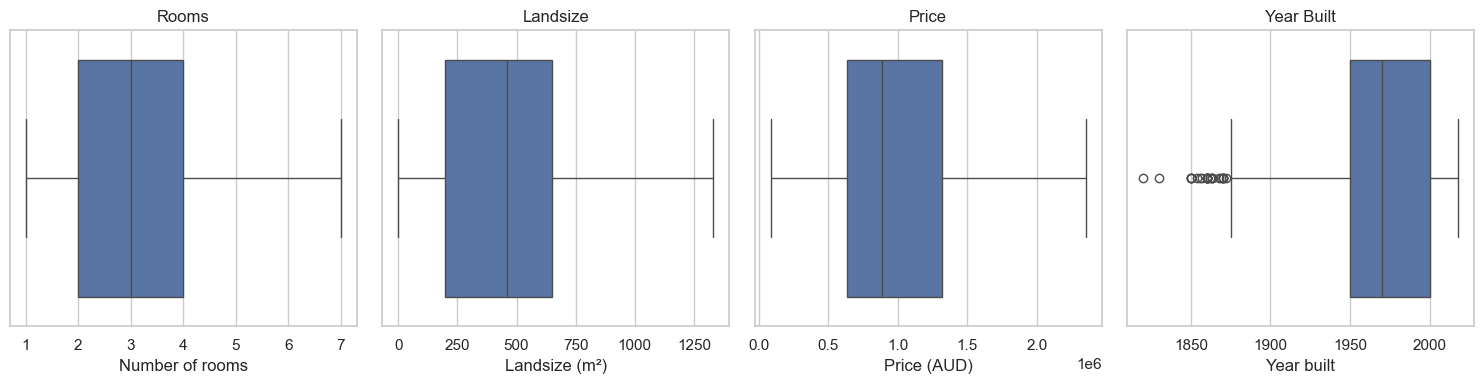

In [35]:
# Re-creating the box plots as before to demonstrate outlier capping:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# 1. Rooms
sns.boxplot(x=df_clean["Rooms"].astype(float), ax=axes[0])
axes[0].set_title("Rooms")
axes[0].set_xlabel("Number of rooms")

# 2. Landsize
sns.boxplot(x=df_clean["Landsize"].astype(float), ax=axes[1])
axes[1].set_title("Landsize")
axes[1].set_xlabel("Landsize (m²)")

# 3. Price
sns.boxplot(x=df_clean["Price"].astype(float), ax=axes[2])
axes[2].set_title("Price")
axes[2].set_xlabel("Price (AUD)")

# 4. YearBuilt
sns.boxplot(x=df_clean["YearBuilt"].astype(float), ax=axes[3])
axes[3].set_title("Year Built")
axes[3].set_xlabel("Year built")

plt.tight_layout()
save_fig("06_boxplots_affected_columns")
plt.show()


In [36]:
# Initiating missing value analysis
missing_report(df_clean).head(12)

,n_missing,pct_missing
Landsize,1463,12.11
Longitude,8,0.07
Latitude,8,0.07
Bathroom,1,0.01
Suburb,0,0.00
Address,0,0.00
Regionname,0,0.00
CouncilArea,0,0.00
YearBuilt,0,0.00
Car,0,0.00


# 4. **Feature Engineering**     
Steps:     
    a. Extract **temporal features** (If necessary)  
    b. **Create** more features depending on the **relation between existing features**.              
    c. Format or transform variables to ensure they are fully model-ready 

In [37]:
# Feature Engineering
# 1. Temporal Features: Extract sale year and month from Date
#    (Date is day/month/year; if it is already datetime this line just keeps it as is)
df_clean["Date"] = pd.to_datetime(df_clean["Date"], format="%d/%m/%Y")
df_clean["SaleYear"] = df_clean["Date"].dt.year
df_clean["SaleMonth"] = df_clean["Date"].dt.month

# Age of the house at the moment it was sold
df_clean["HouseAge"] = df_clean["SaleYear"] - df_clean["YearBuilt"]

# 2. Property Ratios & Indicators:
# How much land each room has (spacious vs. compact properties)
df_clean["LandPerRoom"] = df_clean["Landsize"] / df_clean["Rooms"]

# Bathrooms relative to rooms (higher = more comfortable / higher-end property)
df_clean["BathPerRoom"] = df_clean["Bathroom"] / df_clean["Rooms"]

# Does the property have at least one car space? (1 = yes, 0 = no)
df_clean["HasCarSpace"] = (df_clean["Car"] > 0).astype("Int64")

# Is the property a house (h) rather than a unit (u) or townhouse (t)? (1 = yes, 0 = no)
df_clean["IsHouse"] = (df_clean["Type"] == "h").astype(int)

# 3. Location Feature:
# Group distance to the CBD into zones
df_clean["DistanceZone"] = pd.cut(
    df_clean["Distance"],
    bins=[-0.1, 5, 15, df_clean["Distance"].max()],
    labels=["Inner (0-5 km)", "Middle (5-15 km)", "Outer (15+ km)"]
)

# Display the first few rows with the newly created features
display(df_clean[["Suburb", "SaleYear", "SaleMonth", "HouseAge", "LandPerRoom",
                  "BathPerRoom", "HasCarSpace", "IsHouse", "DistanceZone"]].head())


,Suburb,SaleYear,SaleMonth,HouseAge,LandPerRoom,BathPerRoom,HasCarSpace,IsHouse,DistanceZone
2,Abbotsford,2016,2,116,78.00,0.50,0,1,Inner (0-5 km)
4,Abbotsford,2017,3,117,44.67,0.67,0,1,Inner (0-5 km)
6,Abbotsford,2016,6,2,30.00,0.25,1,1,Inner (0-5 km)
11,Abbotsford,2016,5,106,81.67,0.67,0,1,Inner (0-5 km)
14,Abbotsford,2016,10,126,128.00,0.50,1,1,Inner (0-5 km)


# 5. Comparing raw and clean datasets

In [38]:
# Before / after comparison
comparison = pd.DataFrame(
    {
        "raw": [
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean() * 100,
            df.memory_usage(deep=True).sum() / 1e6,
        ],
        "clean": [
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df_clean.isna().mean().mean() * 100,
            df_clean.memory_usage(deep=True).sum() / 1e6,
        ],
    },
    index=["rows", "columns", "numeric columns", "average % missing", "memory (MB)"],
)
comparison

,raw,clean
rows,"34,857.00","12,078.00"
columns,21.00,28.00
numeric columns,13.00,18.00
average % missing,13.79,0.87
memory (MB),20.23,4.72


# 6. **(EDA)** 
Exploring the data with **descriptive statistics** and **visualizations** (matplotlib + seaborn).

Steps:      
    a.  **Univariate**: one variable at a time    
    b.  **Bivariate**: two variables together       
    c. **Multivariate**: several variables at once    
        - Correlation

In [39]:
key_numeric = df_clean.select_dtypes(include="number").columns.tolist()
key_numeric

stats = df_clean[key_numeric].describe().T

stats["skewness"] = df_clean[key_numeric].skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
Rooms,"12,078.00",3.06,0.96,1.00,2.00,3.00,4.00,7.00,0.20
Price,"12,078.00","1,039,359.47","537,229.54","85,000.00","632,000.00","885,000.00","1,320,000.00","2,352,000.00",0.97
Distance,"12,078.00",10.97,6.02,0.00,6.40,10.30,14.00,25.40,0.72
Bedroom2,"12,078.00",3.05,0.96,0.00,2.00,3.00,4.00,7.00,0.20
Bathroom,"12,077.00",1.63,0.69,1.00,1.00,2.00,2.00,4.00,0.87
Car,"12,078.00",1.67,0.87,0.00,1.00,2.00,2.00,4.00,0.63
Landsize,"10,615.00",450.33,310.32,0.00,197.00,460.00,651.00,"1,332.00",0.51
YearBuilt,"12,078.00","1,966.67",36.09,"1,820.00","1,950.00","1,970.00","2,000.00","2,018.00",-0.59
Latitude,"12,070.00",-37.81,0.09,-38.19,-37.86,-37.80,-37.75,-37.40,-0.30
Longitude,"12,070.00",144.99,0.12,144.42,144.92,145.00,145.07,145.53,-0.35


### a. Univariate analysis

Figure saved to figures\08_univariate_categorical.png


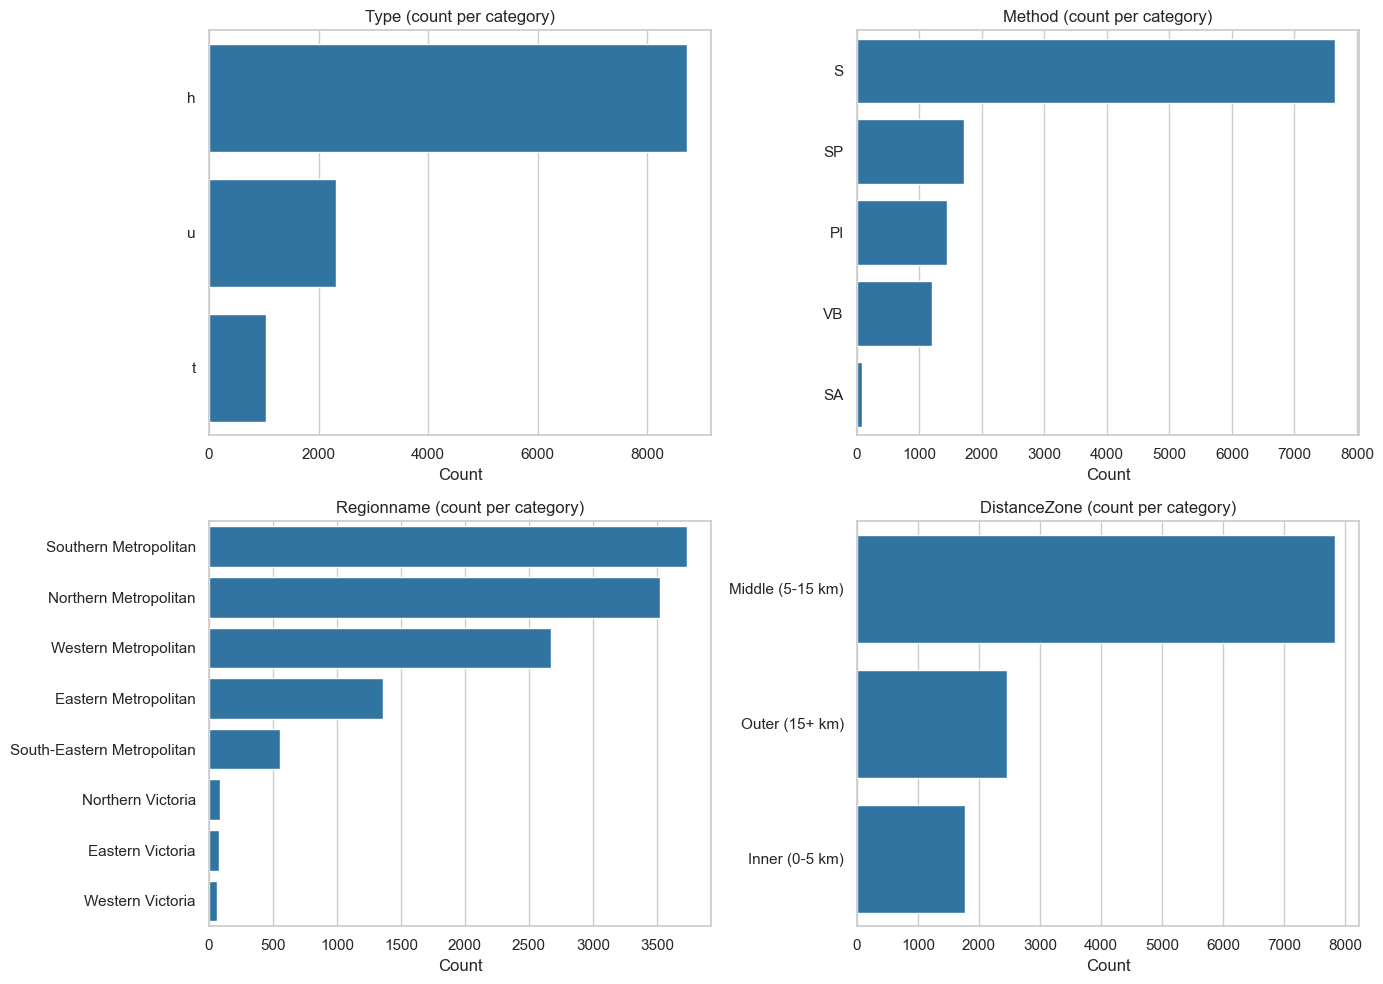

In [41]:
# Univariate Analysis: categorical columns
cat_cols = ["Type", "Method", "Regionname", "DistanceZone"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = df_clean[col].value_counts().index
    sns.countplot(data=df_clean, y=col, order=order, color="tab:blue", ax=axes[i])
    axes[i].set_title(f"{col} (count per category)")
    axes[i].set_xlabel("Count")
    axes[i].set_ylabel("")

plt.tight_layout()
save_fig("08_univariate_categorical")
plt.show()
